# Gaussian processes on discrete data structures

A single kernel measures similarity between variable-length strings and supplies the covariance for both Gaussian process regression and classification. Each pair of letters contributes 1 when they match and 0.5 otherwise. The heatmap divides each covariance by the geometric mean of the two self-similarities.

This example follows the [scikit-learn gallery source](https://github.com/scikit-learn/scikit-learn/blob/4358542a1bd39af2e7e1cbace8b9fed067473c5b/examples/gaussian_process/plot_gpr_on_structured_data.py), by the scikit-learn developers and licensed under BSD-3-Clause. See the [Gaussian process license notices](../../LICENSES/gaussian-process-NOTICES). The gallery bases its kernel on David Haussler's 1999 report *Convolution Kernels on Discrete Structures*.

In [1]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
%matplotlib inline

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents]
            if (p / "notebooks/_support/moxie_nb.py").exists())
sys.path.insert(0, str(ROOT / "notebooks/_support"))
sys.path.insert(0, str(ROOT / "tests/gaussian_process/regression"))
%load_ext moxie_nb
nb = moxie_nb.Session("gaussian_process/plot_gpr_on_structured_data")

from structured_parity import GPR, SequenceKernel, pinned_classifier

## Fit the pinned scikit-learn estimators

Regression fits four sequences and predicts continuous targets for all six. Classification learns from six sequences and predicts whether each of five new sequences contains an A. Both estimators use the gallery's fixed baseline similarity of 0.5.

In [2]:
sequences = np.array(["AGCT", "AGC", "AACT", "TAA", "AAA", "GAACA"])
regression_targets = np.array([1., 1., 2., 2., 3., 3.])
training_idx = [0, 1, 3, 4]
class_train = np.array(["AGCT", "CGA", "TAAC", "TCG", "CTTT", "TGCT"])
class_targets = np.array([True, True, True, False, False, False])
class_query = np.array(["AAA", "ATAG", "CTC", "CT", "C"])
class_truth = np.array([True, True, False, False, False])

nb.share(
    sequences=sequences, regression_train=sequences[training_idx],
    regression_targets=regression_targets[training_idx],
    class_train=class_train, class_targets=class_targets.astype(np.int64),
    class_query=class_query,
)

kernel = SequenceKernel()
gpr = GPR(kernel).fit(sequences[training_idx], regression_targets[training_idx])
gpc = pinned_classifier()(kernel).fit(class_train, class_targets)
regression_mean, regression_std = gpr.predict(sequences, return_std=True)
expected = dict(
    covariance=kernel(sequences), diagonal=kernel.diag(sequences),
    regression_mean=regression_mean, regression_std=regression_std,
    classes=gpc.classes_.astype(np.int64),
    classification=gpc.predict(class_query).astype(np.int64),
    probabilities=gpc.predict_proba(class_query),
)

## Fit both estimators in native Mojo

`KernelContract` declares `List[String]` as the kernel input. The fixed kernel has zero free parameters, so its log-space theta is empty and its optional gradient has zero planes. Both native estimators take the same kernel type. The classifier receives Boolean targets encoded as Int64 values 0 and 1. The notebook uses Python only to exchange arrays, run the reference, compare outputs and draw figures.

In [3]:
%%mojo structured
# Adapted from the scikit-learn gallery by the scikit-learn developers.
# SPDX-License-Identifier: BSD-3-Clause
from numojo import NDArray, Shape, zeros

from moxie.gaussian_process import (
    KernelContract,
    KernelEvaluation,
    StructuredGaussianProcessClassifier,
    StructuredGaussianProcessRegressor,
)
from moxie.gaussian_process.kernels import Hyperparameter
from moxie_nb_io import load, load_strings, save

comptime Dense64 = NDArray[DType.float64]


struct FixedSequenceKernel(KernelContract):
    comptime Input = List[String]
    comptime Params = Float64

    var baseline_similarity: Float64

    def __init__(out self, baseline_similarity: Float64 = 0.5) raises:
        if not (0.0 <= baseline_similarity <= 1.0):
            raise Error("Baseline similarity must lie in [0, 1]")
        self.baseline_similarity = baseline_similarity

    @staticmethod
    def empty_input() -> Self.Input:
        return []

    def get_params(self, deep: Bool = True) -> Self.Params:
        return self.baseline_similarity

    def set_params(mut self, params: Self.Params) raises:
        self = Self(params)

    def hyperparameters(self) raises -> List[Hyperparameter]:
        return [Hyperparameter("baseline_similarity", 1, True, self.bounds())]

    def theta(self) raises -> Dense64:
        return zeros[DType.float64](Shape(0))

    def bounds(self) raises -> Dense64:
        return zeros[DType.float64](Shape(0, 2))

    def set_theta(mut self, theta: Dense64) raises:
        if theta.shape != Shape(0):
            raise Error("FixedSequenceKernel requires empty theta of shape (0,)")

    def clone_with_theta(self, theta: Dense64) raises -> Self:
        var cloned = self.copy()
        cloned.set_theta(theta)
        return cloned^

    def _similarity(self, left: String, right: String) -> Float64:
        var value: Float64 = 0.0
        for a in left.codepoints():
            for b in right.codepoints():
                value += 1.0 if a == b else self.baseline_similarity
        return value

    def _covariance(self, left: Self.Input, right: Self.Input) raises -> Dense64:
        var covariance = zeros[DType.float64](Shape(len(left), len(right)))
        for i in range(len(left)):
            for j in range(len(right)):
                value = self._similarity(left[i], right[j])
                covariance.unsafe_set(i * len(right) + j, value)
        return covariance^

    def evaluate(
        self, X: Self.Input, Y: Optional[Self.Input] = None, eval_gradient: Bool = False,
    ) raises -> KernelEvaluation:
        if Y:
            if eval_gradient:
                raise Error("Kernel gradients require Y=None")
            return KernelEvaluation(self._covariance(X, Y.value()), None)
        var covariance = self._covariance(X, X)
        if eval_gradient:
            return KernelEvaluation(covariance^, zeros[DType.float64](Shape(len(X), len(X), 0)))
        return KernelEvaluation(covariance^, None)

    def diag(self, X: Self.Input) raises -> Dense64:
        var diagonal = zeros[DType.float64](Shape(len(X)))
        for i in range(len(X)):
            diagonal.unsafe_set(i, self._similarity(X[i], X[i]))
        return diagonal^

    def is_stationary(self) -> Bool:
        return False

    def requires_vector_input(self) -> Bool:
        return False


def main() raises:
    var sequences = load_strings("sequences")
    var kernel = FixedSequenceKernel(0.5)
    save("covariance", kernel.evaluate(sequences).take_covariance())
    save("diagonal", kernel.diag(sequences))

    var gpr = StructuredGaussianProcessRegressor[FixedSequenceKernel](kernel)
    _ = gpr.fit(load_strings("regression_train"), load("regression_targets"))
    var regression = gpr.predict(sequences, return_std=True)
    save("regression_mean", regression.mean)
    save("regression_std", regression.std.value())

    var gpc = StructuredGaussianProcessClassifier[FixedSequenceKernel, String](kernel)
    _ = gpc.fit(load_strings("class_train"), load[DType.int64]("class_targets"))
    var class_query = load_strings("class_query")
    save("classes", gpc.classes_())
    save("classification", gpc.predict(class_query))
    save("probabilities", gpc.predict_proba(class_query))

## Check parity

Kernel entries and predicted class labels should agree exactly. Regression and probability comparisons allow for Float64 factorization, solve and scalar-function rounding.

In [4]:
native = nb.results["structured"]
for key, reference in expected.items():
    assert native[key].dtype == reference.dtype, key
    if key in ("covariance", "diagonal", "classes", "classification"):
        nb.compare(key, reference, native[key], exact=True)
    elif key == "regression_std":
        nb.compare(key, reference, native[key], rtol=2e-11, atol=3e-10,
                   reason="Square root magnifies Float64 cancellation near zero variance")
    else:
        nb.compare(key, reference, native[key], rtol=2e-11, atol=2e-11,
                   reason="Float64 factorization, solve and scalar-function rounding")
nb.report()
nb.assert_parity()

check,status,sklearn shape,moxie shape,max |diff|,max rel,tolerance,detail,tolerance reason
covariance,PASS,"(6, 6)","(6, 6)",,,exact,0 mismatches,
diagonal,PASS,"(6,)","(6,)",,,exact,0 mismatches,
regression_mean,PASS,"(6,)","(6,)",2.22e-15,2.22e-15,"rtol=2e-11, atol=2e-11",,"Float64 factorization, solve and scalar-function rounding"
regression_std,PASS,"(6,)","(6,)",1.53e-10,1.31e-05,"rtol=2e-11, atol=3e-10",,Square root magnifies Float64 cancellation near zero variance
classes,PASS,"(2,)","(2,)",,,exact,0 mismatches,
classification,PASS,"(5,)","(5,)",,,exact,0 mismatches,
probabilities,PASS,"(5, 2)","(5, 2)",1.71e-13,5.63e-13,"rtol=2e-11, atol=2e-11",,"Float64 factorization, solve and scalar-function rounding"


## Sequence similarity

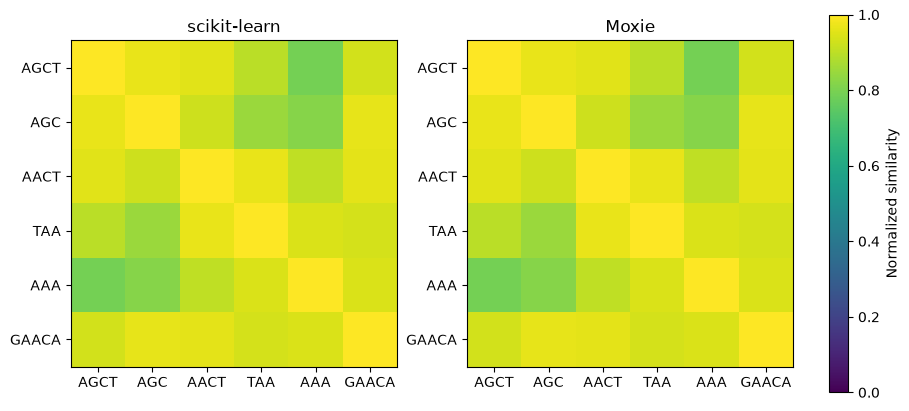

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(9, 4), layout="constrained")
for ax, (name, result) in zip(axes, [("scikit-learn", expected), ("Moxie", native)]):
    similarity = result["covariance"] / np.sqrt(np.outer(result["diagonal"], result["diagonal"]))
    image = ax.imshow(similarity, vmin=0, vmax=1)
    ax.set(xticks=np.arange(len(sequences)), xticklabels=sequences,
           yticks=np.arange(len(sequences)), yticklabels=sequences, title=name)
fig.colorbar(image, ax=axes, label="Normalized similarity")
plt.show()

## Regression on sequences

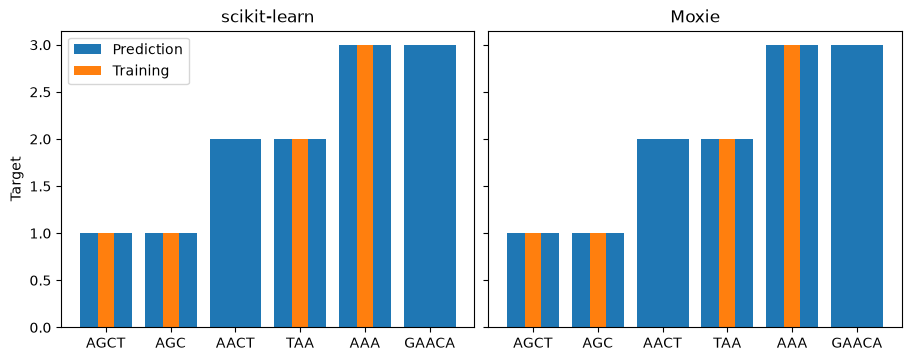

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(9, 3.5), sharey=True, layout="constrained")
for ax, (name, result) in zip(axes, [("scikit-learn", expected), ("Moxie", native)]):
    ax.bar(np.arange(len(sequences)), result["regression_mean"], label="Prediction")
    ax.bar(training_idx, regression_targets[training_idx], width=0.25, label="Training")
    ax.set(xticks=np.arange(len(sequences)), xticklabels=sequences, title=name)
axes[0].set_ylabel("Target")
axes[0].legend()
plt.show()

## Classification on sequences

Both models classify four of the five test sequences correctly. They predict that `C` contains an A.

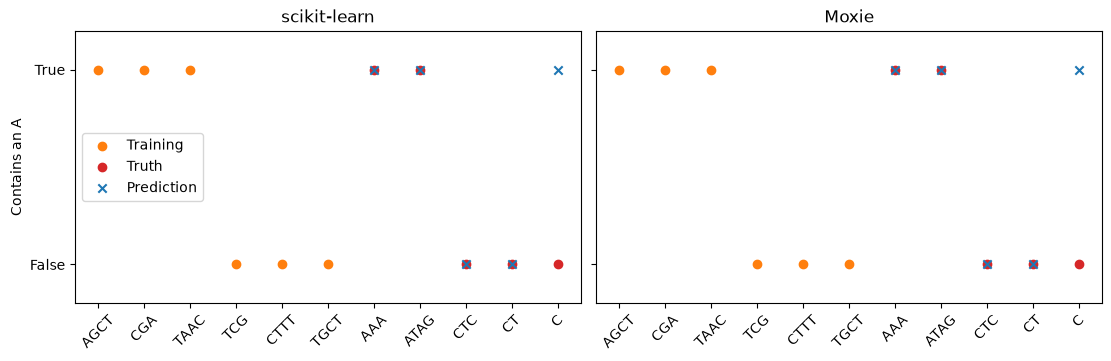

In [7]:
class_names = np.concatenate((class_train, class_query))
train_positions = np.arange(len(class_train))
query_positions = len(class_train) + np.arange(len(class_query))
np.testing.assert_array_equal(np.flatnonzero(native["classification"] != class_truth), [4])

fig, axes = plt.subplots(1, 2, figsize=(11, 3.5), sharey=True, layout="constrained")
for ax, (name, result) in zip(axes, [("scikit-learn", expected), ("Moxie", native)]):
    ax.scatter(train_positions, class_targets, label="Training", color="tab:orange")
    ax.scatter(query_positions, class_truth, label="Truth", color="tab:red")
    ax.scatter(query_positions, result["classification"], label="Prediction",
               color="tab:blue", marker="x")
    ax.set(xticks=np.arange(len(class_names)), xticklabels=class_names,
           yticks=[0, 1], yticklabels=["False", "True"], ylim=(-0.2, 1.2), title=name)
    ax.tick_params(axis="x", labelrotation=45)
axes[0].set_ylabel("Contains an A")
axes[0].legend(loc="center left")
plt.show()